# T1-4b: Pure Strain — Interpolator Comparison incl. Least-Squares Face Reconstruction

## Verification Study — Tier 1 / Trivial Trajectories

**Field:** $u = \varepsilon\,x$, $v = -\varepsilon\,y$  &nbsp;&nbsp; **Analytical trajectory:** $x(t) = x_0\,e^{\varepsilon t}$, $y(t) = y_0\,e^{-\varepsilon t}$

Same flow, grid and particles as **T1-4**, but comparing the three lateral interpolation schemes used in
`interpolation_comparison_DBG_fesom.ipynb`:

| Scheme | Data location | Interpolator | Order in space |
|---|---|---|---|
| barycentric (node) | `n_node` | `UxLinearNodeConstantZC` (Parcels built-in) | linear |
| constant (face) | `n_face` | `UxConstantFaceConstantZC` (Parcels built-in) | piecewise constant |
| least-squares (face) | `n_face` | `LinearFaceRecon` (custom, defined below) | linear (reconstructed) |

**Expectation:** the pure-strain field is *linear*, so both the barycentric node scheme and the least-squares
face reconstruction should reproduce it exactly — their trajectory errors should come from the time
integrator only. The piecewise-constant face scheme has an $O(\Delta x)$ spatial error that does not
converge with $\Delta t$.

Each scheme is tested with Euler (`AdvectionEE`) and RK4 (`AdvectionRK4`).

In [1]:
import math
import os
import shutil

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import uxarray as ux
import xarray as xr

import parcels
from parcels._core.particle import get_default_particle

# Parcels' default Particle stores positions in float32 (~1e-6 deg resolution);
# use float64 positions so the error tolerances below are meaningful.
Particle64 = get_default_particle(np.float64)
from uxarray.constants import INT_FILL_VALUE
from parcels.interpolators._base import ScalarInterpolator

## 1. Parameters

In [2]:
# Domain (centered at origin = stagnation point)
NX = 40
HALF = 5.0
LON_MIN, LON_MAX = -HALF, HALF
LAT_MIN, LAT_MAX = -HALF, HALF

# Strain rate
EPSILON = 1e-3  # s^{-1}

# Time — must be divisible by all DT_VALUES in the convergence study,
# and short enough that all particles stay inside the domain.
# x(T) = x0 * exp(eps*T). For x0=3, T=360: x(T) = 3*exp(0.36) ~ 4.30
# LCM(120,60,30,15,5) = 120; 360 = 3*120.
T_TOTAL_S = 360.0
T_TOTAL = np.timedelta64(int(T_TOTAL_S), "s")
DT_BASE = np.timedelta64(30, "s")

# Single-snapshot velocity (steady field)
N_TIMESTEPS = 1
TIME = xr.date_range("2000-01-01", periods=N_TIMESTEPS, freq="2h")

# Particle initial positions:
# - Near stagnation point (small displacements from origin)
# - Moderate distance
# - Far from origin (will experience strong stretching)
p_coords_near = [
    (0.1, 0.1), (-0.1, 0.1), (0.1, -0.1), (-0.1, -0.1),
    (0.05, 0.2), (0.2, 0.05),
]
p_coords_mid = [
    (1.0, 1.0), (-1.0, 1.0), (1.0, -1.0), (-1.0, -1.0),
    (0.5, 2.0), (2.0, 0.5),
]
p_coords_far = [
    (3.0, 1.0), (-3.0, 1.0), (1.0, 3.0), (1.0, -3.0),
    (2.5, 2.5), (-2.5, -2.5),
]

all_coords = p_coords_near + p_coords_mid + p_coords_far
p_lon0 = np.array([c[0] for c in all_coords], dtype=np.float64)
p_lat0 = np.array([c[1] for c in all_coords], dtype=np.float64)
N_PARTICLES = len(p_lon0)

# Labels for particle groups
n_near = len(p_coords_near)
n_mid = len(p_coords_mid)
n_far = len(p_coords_far)
particle_group = (
    ["near"] * n_near + ["mid"] * n_mid + ["far"] * n_far
)

print(f"\u03b5 = {EPSILON:.1e} s^-1")
print(f"Total runtime = {T_TOTAL_S:.0f} s")
print(f"exp(\u03b5*T) = {np.exp(EPSILON * T_TOTAL_S):.4f}")
print(f"{N_PARTICLES} particles: {n_near} near, {n_mid} mid, {n_far} far")

ε = 1.0e-03 s^-1
Total runtime = 360 s
exp(ε*T) = 1.4333
18 particles: 6 near, 6 mid, 6 far


## 2. Build Unstructured Grid

In [3]:
lon, lat = np.meshgrid(
    np.linspace(LON_MIN, LON_MAX, NX, dtype=np.float64),
    np.linspace(LAT_MIN, LAT_MAX, NX, dtype=np.float64),
)
lon_flat = lon.ravel()
lat_flat = lat.ravel()

mask = (
    np.isclose(lon_flat, LON_MIN)
    | np.isclose(lon_flat, LON_MAX)
    | np.isclose(lat_flat, LAT_MIN)
    | np.isclose(lat_flat, LAT_MAX)
)
boundary_points = np.flatnonzero(mask)

uxgrid = ux.Grid.from_points(
    (lon_flat, lat_flat),
    method="regional_delaunay",
    boundary_points=boundary_points,
)
uxgrid.attrs["Conventions"] = "UGRID-1.0"

print(f"Grid: {uxgrid.n_node} nodes, {uxgrid.n_face} faces")

Grid: 1600 nodes, 3039 faces


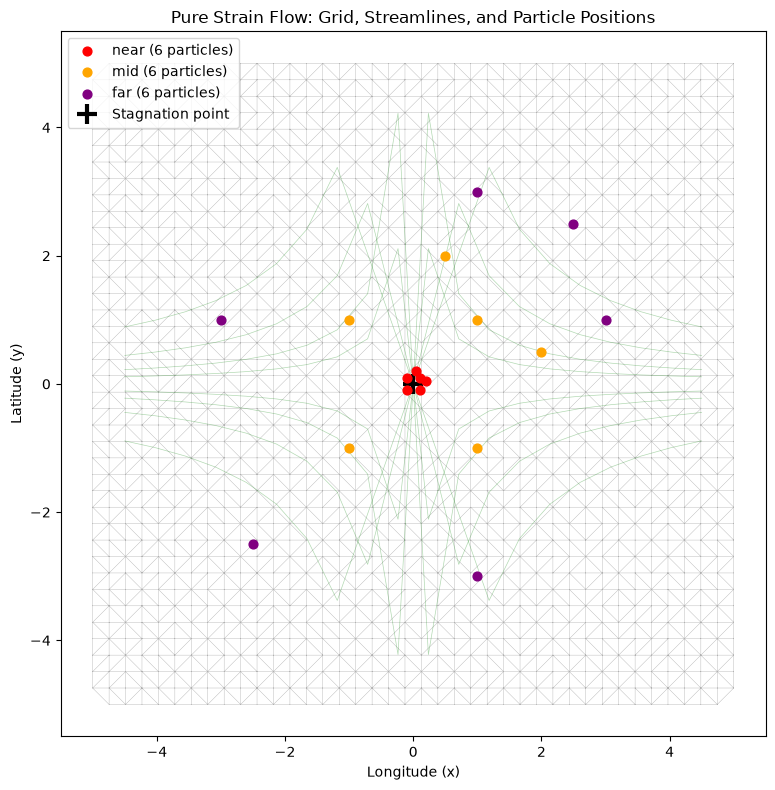

In [4]:
# Visualize grid, particle positions, and flow structure
fig, ax = plt.subplots(figsize=(8, 8))

triang = mtri.Triangulation(
    uxgrid.node_lon.values, uxgrid.node_lat.values,
    triangles=uxgrid.face_node_connectivity.values,
)
ax.triplot(triang, "k-", lw=0.3, alpha=0.3)

# Streamlines of the hyperbolic flow (xy = const)
x_stream = np.linspace(-4.5, 4.5, 20)
for c in [0.5, 1.0, 2.0, 4.0]:
    y_pos = c / x_stream
    y_neg = -c / x_stream
    valid = np.abs(y_pos) < HALF
    ax.plot(x_stream[valid], y_pos[valid], "g-", lw=0.5, alpha=0.3)
    ax.plot(x_stream[valid], y_neg[valid], "g-", lw=0.5, alpha=0.3)

# Color particles by group
colors_group = {"near": "red", "mid": "orange", "far": "purple"}
for group in ["near", "mid", "far"]:
    idx = [i for i, g in enumerate(particle_group) if g == group]
    ax.scatter(p_lon0[idx], p_lat0[idx], c=colors_group[group], s=40,
               zorder=5, label=f"{group} ({len(idx)} particles)")

ax.plot(0, 0, "k+", ms=15, mew=3, label="Stagnation point")
ax.set_xlabel("Longitude (x)")
ax.set_ylabel("Latitude (y)")
ax.set_title("Pure Strain Flow: Grid, Streamlines, and Particle Positions")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 3. Define Velocity Fields

Pure strain (hyperbolic) flow:
$$u = \varepsilon\,x, \quad v = -\varepsilon\,y$$

This is a linear field, so barycentric (node-centered) interpolation reproduces it exactly.
The flow is incompressible ($\nabla \cdot \mathbf{u} = 0$) and irrotational
($\nabla \times \mathbf{u} = 0$).

In [5]:
zf = np.array([0.0, 1.0], dtype=np.float64)
zc = np.array([0.5], dtype=np.float64)


def make_face_centered_dataset(uxgrid, epsilon):
    """Velocity on face centers: u = epsilon*x_face, v = -epsilon*y_face."""
    face_lon = uxgrid.face_lon.values
    face_lat = uxgrid.face_lat.values

    u_vals = epsilon * face_lon
    v_vals = -epsilon * face_lat

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_face)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (pure strain)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_face"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="face", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (pure strain)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


def make_node_centered_dataset(uxgrid, epsilon):
    """Velocity on corner nodes: u = epsilon*x_node, v = -epsilon*y_node."""
    node_lon = uxgrid.node_lon.values
    node_lat = uxgrid.node_lat.values

    u_vals = epsilon * node_lon
    v_vals = -epsilon * node_lat

    U = np.broadcast_to(u_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    V = np.broadcast_to(v_vals[np.newaxis, np.newaxis, :],
                        (N_TIMESTEPS, zc.size, uxgrid.n_node)).copy()
    W = np.zeros((N_TIMESTEPS, zf.size, uxgrid.n_node), dtype=np.float64)

    u = ux.UxDataArray(
        data=U, name="U", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="zonal velocity (pure strain)"),
    )
    v = ux.UxDataArray(
        data=V, name="V", uxgrid=uxgrid,
        dims=["time", "zc", "n_node"],
        coords=dict(time=(["time"], TIME), zc=(["zc"], zc)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="meridional velocity (pure strain)"),
    )
    w = ux.UxDataArray(
        data=W, name="W", uxgrid=uxgrid,
        dims=["time", "zf", "n_node"],
        coords=dict(time=(["time"], TIME), zf=(["zf"], zf)),
        attrs=dict(location="node", mesh="delaunay", Conventions="UGRID-1.0",
                   units="degrees/s", description="vertical velocity"),
    )
    return ux.UxDataset({"U": u, "V": v, "W": w}, uxgrid=uxgrid)


ds_face = make_face_centered_dataset(uxgrid, EPSILON)
ds_node = make_node_centered_dataset(uxgrid, EPSILON)

print("Face-centered dataset:")
print(ds_face)
print()
print("Node-centered dataset:")
print(ds_node)

Face-centered dataset:
<xarray.UxDataset> Size: 74kB
Dimensions:  (time: 1, zc: 1, n_face: 3039, zf: 2, n_node: 1600)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_face, n_node
Data variables:
    U        (time, zc, n_face) float64 24kB -0.004915 -0.004829 ... 0.001496
    V        (time, zc, n_face) float64 24kB 0.0004701 0.0005556 ... 0.002778
    W        (time, zf, n_node) float64 26kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

Node-centered dataset:
<xarray.UxDataset> Size: 51kB
Dimensions:  (time: 1, zc: 1, n_node: 1600, zf: 2)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-01-01
  * zc       (zc) float64 8B 0.5
  * zf       (zf) float64 16B 0.0 1.0
Dimensions without coordinates: n_node
Data variables:
    U        (time, zc, n_node) float64 13kB -0.005 -0.004744 ... 0.004744 0.005
    V        (time, zc, n_node) float64 13kB 0.005 0.005 0.005 ... -0.005 -

## 4. Analytical Solution

For the pure strain field $\mathbf{u} = (\varepsilon x,\; -\varepsilon y)$, a particle
starting at $(x_0, y_0)$ follows:

$$x(t) = x_0\,e^{\varepsilon t}, \quad y(t) = y_0\,e^{-\varepsilon t}$$

Key properties:
- **Area-preserving:** $x(t) \cdot y(t) = x_0 \cdot y_0$ (hyperbolic invariant)
- **Stretching along $x$-axis**, compression along $y$-axis
- **Stagnation point** at the origin: particles placed exactly at $(0,0)$ remain there
- **Error amplification:** truncation errors grow as $e^{\varepsilon t}$ in the stretching
  direction

In [6]:
def analytical_position(lon0, lat0, epsilon, dt_seconds):
    """Exact particle position after dt_seconds of pure strain flow."""
    return lon0 * np.exp(epsilon * dt_seconds), lat0 * np.exp(-epsilon * dt_seconds)


def analytical_trajectory(lon0, lat0, epsilon, t_array):
    """Exact trajectory at an array of times (seconds)."""
    return (lon0 * np.exp(epsilon * t_array),
            lat0 * np.exp(-epsilon * t_array))

## 5. Least-Squares Face Reconstruction Interpolator

Ported from `interpolation_comparison_DBG_fesom.ipynb` (`build_reconstruction_terms` + `LinearFaceRecon`)
to the current Parcels interpolator API, where an interpolator is a `ScalarInterpolator` subclass with an
`interp(particle_positions, grid_positions, field)` method and positions are named `x`, `y`, `z`.

For each face $c$ we fit a planar gradient $(a_x, a_y)$ to the differences $u_k - u_c$ with its
neighbouring faces $k$ (offsets $\delta x_k, \delta y_k$ between face centroids), by least squares:

$$\begin{pmatrix} \sum \delta x^2 & \sum \delta x\,\delta y \\ \sum \delta x\,\delta y & \sum \delta y^2 \end{pmatrix}
\begin{pmatrix} a_x \\ a_y \end{pmatrix} = \begin{pmatrix} \sum \delta x\,(u_k-u_c) \\ \sum \delta y\,(u_k-u_c) \end{pmatrix}$$

and evaluate $u(\mathbf{x}_p) = u_c + a_x\,(x_p - x_c) + a_y\,(y_p - y_c)$. The coefficients multiplying
$(u_k - u_c)$ depend only on the geometry, so they are precomputed once per face in `__init__`
(instead of being stored on `uxgrid._ds` as in the FESOM notebook). Faces with fewer than two independent
neighbours fall back to the piecewise-constant value.

In [7]:
DEG2M = 1852.0 * 60.0  # metres per degree (matches the Ux_Velocity unit conversion)


class LinearFaceRecon(ScalarInterpolator):
    """Linear least-squares reconstruction of face-registered data, constant in the vertical (zc)."""

    def __init__(self, uxgrid, spherical=False):
        self.spherical = spherical
        nbr = np.asarray(uxgrid.face_face_connectivity.values)          # (n_face, K)
        self.face_x = np.asarray(uxgrid.face_lon.values, dtype=np.float64)
        self.face_y = np.asarray(uxgrid.face_lat.values, dtype=np.float64)

        valid = nbr != INT_FILL_VALUE
        nbr_safe = np.where(valid, nbr, 0)
        dx, dy = self._offsets(self.face_x[:, None], self.face_y[:, None],
                               self.face_x[nbr_safe], self.face_y[nbr_safe])
        dx = np.where(valid, dx, 0.0)  # absent neighbour -> no contribution
        dy = np.where(valid, dy, 0.0)

        X2 = np.sum(dx * dx, axis=1)
        Y2 = np.sum(dy * dy, axis=1)
        XY = np.sum(dx * dy, axis=1)
        det = X2 * Y2 - XY * XY

        # < 2 independent neighbours -> singular system -> zero-gradient (piecewise-constant) fallback
        ok = det > 1e-12 * np.maximum(X2 * Y2, np.finfo(float).tiny)
        inv_det = np.where(ok, 1.0 / np.where(ok, det, 1.0), 0.0)

        self.gx = np.where(valid, (dx * Y2[:, None] - dy * XY[:, None]) * inv_det[:, None], 0.0)
        self.gy = np.where(valid, (dy * X2[:, None] - dx * XY[:, None]) * inv_det[:, None], 0.0)
        self.neighbors = nbr_safe
        self.mask = valid.astype(np.float64)
        self.n_fallback = int(np.sum(~ok))

    def _offsets(self, x_c, y_c, x, y):
        """Local planar offset of (x, y) from (x_c, y_c): metres on a sphere, grid units on a flat mesh."""
        if self.spherical:
            dlon = ((np.asarray(x) - x_c + 180.0) % 360.0) - 180.0
            return dlon * np.cos(np.deg2rad(y_c)) * DEG2M, (np.asarray(y) - y_c) * DEG2M
        return np.asarray(x) - x_c, np.asarray(y) - y_c

    def interp(self, particle_positions, grid_positions, field):
        ti, zi, fi = np.broadcast_arrays(
            grid_positions["T"]["index"], grid_positions["Z"]["index"], grid_positions["FACE"]["index"]
        )
        data = np.asarray(field.data.values)                            # (time, zc, n_face)

        u_c = data[ti, zi, fi]                                          # (M,)
        u_k = data[ti[:, None], zi[:, None], self.neighbors[fi]]        # (M, K)
        du = (u_k - u_c[:, None]) * self.mask[fi]
        a_x = np.sum(self.gx[fi] * du, axis=1)
        a_y = np.sum(self.gy[fi] * du, axis=1)

        dx, dy = self._offsets(self.face_x[fi], self.face_y[fi],
                               particle_positions["x"], particle_positions["y"])
        return u_c + a_x * dx + a_y * dy

In [8]:
def make_fieldset(scheme):
    """Fresh FieldSet for one interpolation scheme."""
    if scheme == "barycentric (node)":
        return parcels.FieldSet.from_ugrid_conventions(ds_node, mesh="flat")
    fieldset = parcels.FieldSet.from_ugrid_conventions(ds_face, mesh="flat")
    if scheme == "least-squares (face)":
        recon = LinearFaceRecon(fieldset.fields["U"].grid.uxgrid, spherical=False)
        fieldset.fields["U"].interp_method = recon
        fieldset.fields["V"].interp_method = recon
    return fieldset

#
SCHEMES = ["barycentric (node)", "constant (face)", "least-squares (face)"]
SCHEME_COLORS = {"barycentric (node)": "C0", "constant (face)": "C1", "least-squares (face)": "C2"}

for scheme in SCHEMES:
    fs = make_fieldset(scheme)
    print(f"{scheme:22s} U -> {type(fs.fields['U'].interp_method).__name__:26s}"
          f" V -> {type(fs.fields['V'].interp_method).__name__}")
print(f"\nleast-squares fallback faces: "
      f"{LinearFaceRecon(uxgrid).n_fallback} of {uxgrid.n_face}")

barycentric (node)     U -> UxLinearNodeConstantZC     V -> UxLinearNodeConstantZC
constant (face)        U -> UxConstantFaceConstantZC   V -> UxConstantFaceConstantZC
least-squares (face)   U -> LinearFaceRecon            V -> LinearFaceRecon

least-squares fallback faces: 0 of 3039


## 6. Direct Interpolation Error (no time stepping)

Before advecting, sample each scheme's `U` and `V` at random points and compare with the exact
field. This isolates the spatial interpolation error from the time integrator.

In [9]:
rng = np.random.default_rng(0)
N_SAMPLE = 20000
xs = rng.uniform(LON_MIN + 0.5, LON_MAX - 0.5, N_SAMPLE)
ys = rng.uniform(LAT_MIN + 0.5, LAT_MAX - 0.5, N_SAMPLE)
zs = np.full(N_SAMPLE, zc[0])

interp_results = []
for scheme in SCHEMES:
    fs = make_fieldset(scheme)
    u = fs.fields["U"].eval(0.0, zs, ys, xs)
    v = fs.fields["V"].eval(0.0, zs, ys, xs)
    err = np.hypot(u - EPSILON * xs, v + EPSILON * ys)
    interp_results.append({"scheme": scheme, "max_velocity_error": err.max(),
                           "rms_velocity_error": np.sqrt(np.mean(err**2))})
    print(f"{scheme:22s} | max |u - u_exact| = {err.max():.3e}   rms = {np.sqrt(np.mean(err**2)):.3e}")

df_interp = pd.DataFrame(interp_results)
df_interp

barycentric (node)     | max |u - u_exact| = 4.728e-10   rms = 1.146e-10
constant (face)        | max |u - u_exact| = 1.904e-04   rms = 8.551e-05


least-squares (face)   | max |u - u_exact| = 1.227e-18   rms = 3.053e-19


,scheme,max_velocity_error,rms_velocity_error
0,barycentric (node),4.728140e-10,1.145730e-10
1,constant (face),1.904080e-04,8.551322e-05
2,least-squares (face),1.226635e-18,3.053176e-19


## 7. Run Advection: All Interpolator / Time Integrator Combinations

In [10]:
time_integrators = {
    "EE": parcels.kernels.AdvectionEE,
    "RK4": parcels.kernels.AdvectionRK4,
}

results = []
output_files = {}

for scheme in SCHEMES:
    fieldset = make_fieldset(scheme)

    for integrator_label, integrator in time_integrators.items():
        tag = scheme.split(" ")[0]
        out_name = f"T1_4b_{tag}_{integrator_label}.parquet"

        pset = parcels.ParticleSet(
            fieldset,
            pclass=Particle64,
            x=p_lon0.copy(),
            y=p_lat0.copy(),
        )
        pfile = parcels.ParticleFile(path=out_name, outputdt=DT_BASE, mode="w")
        pset.execute(
            integrator,
            runtime=T_TOTAL,
            dt=DT_BASE,
            output_file=pfile,
            verbose_progress=False,
        )

        lon_exact, lat_exact = analytical_position(p_lon0, p_lat0, EPSILON, T_TOTAL_S)
        pos_err = np.sqrt((pset.x - lon_exact)**2 + (pset.y - lat_exact)**2)
        xy_err = np.abs(pset.x * pset.y - p_lon0 * p_lat0)  # hyperbolic invariant

        key = f"{scheme} / {integrator_label}"
        output_files[key] = out_name
        results.append({
            "scheme": scheme,
            "integrator": integrator_label,
            "output": out_name,
            "max_position_error": np.max(pos_err),
            "max_xy_invariant_error": np.max(xy_err),
            "max_err_near": np.max(pos_err[:n_near]),
            "max_err_mid": np.max(pos_err[n_near:n_near + n_mid]),
            "max_err_far": np.max(pos_err[n_near + n_mid:]),
        })
        print(f"{scheme:22s} | {integrator_label:4s} | max |err| = {np.max(pos_err):.4e}  "
              f"max |xy err| = {np.max(xy_err):.4e}  "
              f"(near={np.max(pos_err[:n_near]):.2e}, mid={np.max(pos_err[n_near:n_near+n_mid]):.2e}, "
              f"far={np.max(pos_err[n_near+n_mid:]):.2e})")

INFO: Output files are stored in T1_4b_barycentric_EE.parquet


barycentric (node)     | EE   | max |err| = 2.3027e-02  max |xy err| = 6.7167e-02  (near=1.53e-03, mid=1.53e-02, far=2.30e-02)
INFO: Output files are stored in T1_4b_barycentric_RK4.parquet


barycentric (node)     | RK4  | max |err| = 1.1102e-08  max |xy err| = 7.7164e-09  (near=4.65e-10, mid=6.27e-09, far=1.11e-08)
INFO: Output files are stored in T1_4b_constant_EE.parquet


constant (face)        | EE   | max |err| = 6.0566e-02  max |xy err| = 7.1992e-02  (near=6.06e-02, mid=2.31e-02, far=2.75e-02)
INFO: Output files are stored in T1_4b_constant_RK4.parquet


constant (face)        | RK4  | max |err| = 6.0566e-02  max |xy err| = 1.9037e-02  (near=6.06e-02, mid=1.37e-02, far=8.04e-03)
INFO: Output files are stored in T1_4b_least-squares_EE.parquet


least-squares (face)   | EE   | max |err| = 2.3027e-02  max |xy err| = 6.7167e-02  (near=1.53e-03, mid=1.53e-02, far=2.30e-02)
INFO: Output files are stored in T1_4b_least-squares_RK4.parquet


least-squares (face)   | RK4  | max |err| = 1.0338e-08  max |xy err| = 7.5946e-10  (near=6.85e-10, mid=6.85e-09, far=1.03e-08)


## 8. Results Summary

In [11]:
df = pd.DataFrame(results)
df

,scheme,integrator,output,max_position_error,max_xy_invariant_error,max_err_near,max_err_mid,max_err_far
0,barycentric (node),EE,T1_4b_barycentric_EE.parquet,2.302701e-02,6.716690e-02,1.525795e-03,1.525795e-02,2.302701e-02
1,barycentric (node),RK4,T1_4b_barycentric_RK4.parquet,1.110159e-08,7.716422e-09,4.645029e-10,6.273533e-09,1.110159e-08
2,constant (face),EE,T1_4b_constant_EE.parquet,6.056573e-02,7.199157e-02,6.056573e-02,2.307379e-02,2.751625e-02
3,constant (face),RK4,T1_4b_constant_RK4.parquet,6.056573e-02,1.903700e-02,6.056573e-02,1.367345e-02,8.041327e-03
4,least-squares (face),EE,T1_4b_least-squares_EE.parquet,2.302700e-02,6.716688e-02,1.525796e-03,1.525796e-02,2.302700e-02
5,least-squares (face),RK4,T1_4b_least-squares_RK4.parquet,1.033826e-08,7.594636e-10,6.849418e-10,6.849419e-09,1.033826e-08


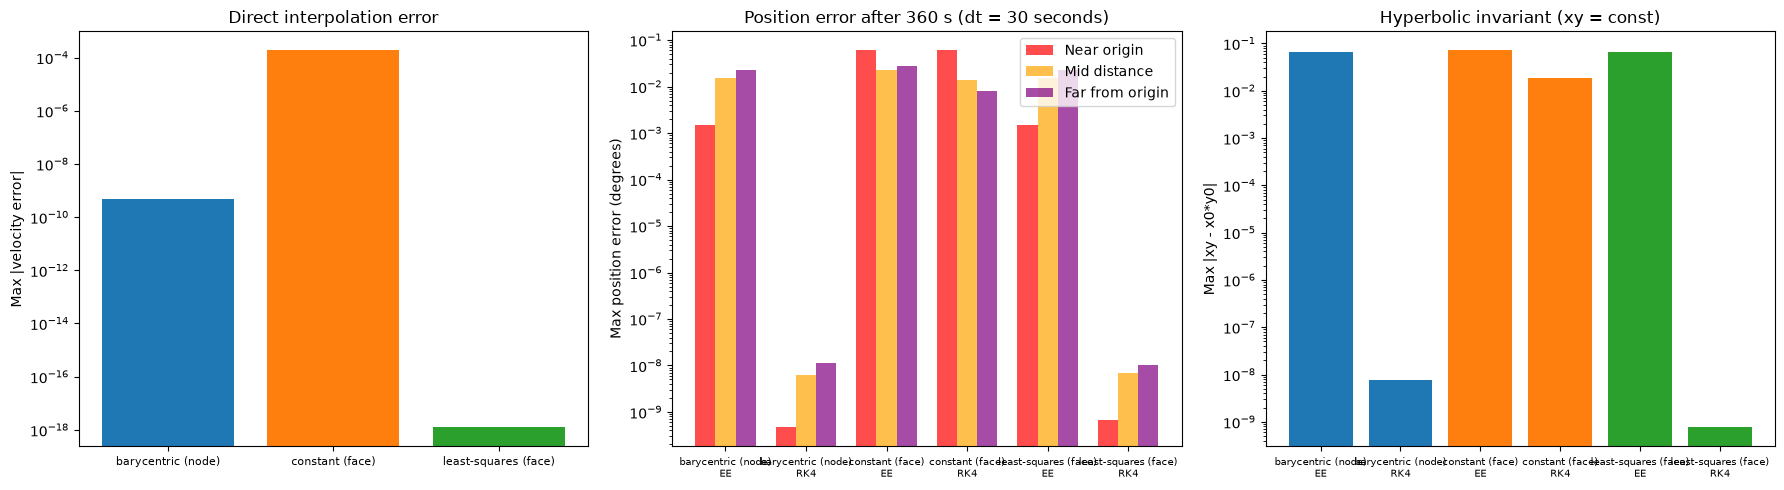

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels = [f"{r['scheme']}\n{r['integrator']}" for r in results]
colors = [SCHEME_COLORS[r["scheme"]] for r in results]
x_pos = np.arange(len(results))

ax = axes[0]
ax.bar(range(len(df_interp)), df_interp["max_velocity_error"],
       color=[SCHEME_COLORS[s] for s in df_interp["scheme"]])
ax.set_xticks(range(len(df_interp)))
ax.set_xticklabels(df_interp["scheme"], fontsize=8)
ax.set_ylabel("Max |velocity error|")
ax.set_title("Direct interpolation error")
ax.set_yscale("log")

ax = axes[1]
width = 0.25
ax.bar(x_pos - width, [r["max_err_near"] for r in results], width, label="Near origin", color="red", alpha=0.7)
ax.bar(x_pos, [r["max_err_mid"] for r in results], width, label="Mid distance", color="orange", alpha=0.7)
ax.bar(x_pos + width, [r["max_err_far"] for r in results], width, label="Far from origin", color="purple", alpha=0.7)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Max position error (degrees)")
ax.set_title(f"Position error after {T_TOTAL_S:.0f} s (dt = {DT_BASE})")
ax.set_yscale("log")
ax.legend()

ax = axes[2]
ax.bar(x_pos, [r["max_xy_invariant_error"] for r in results], color=colors)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Max |xy - x0*y0|")
ax.set_title("Hyperbolic invariant (xy = const)")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## 9. Trajectory Visualization

Computed trajectories (colour = scheme) against the analytical hyperbolas (red).

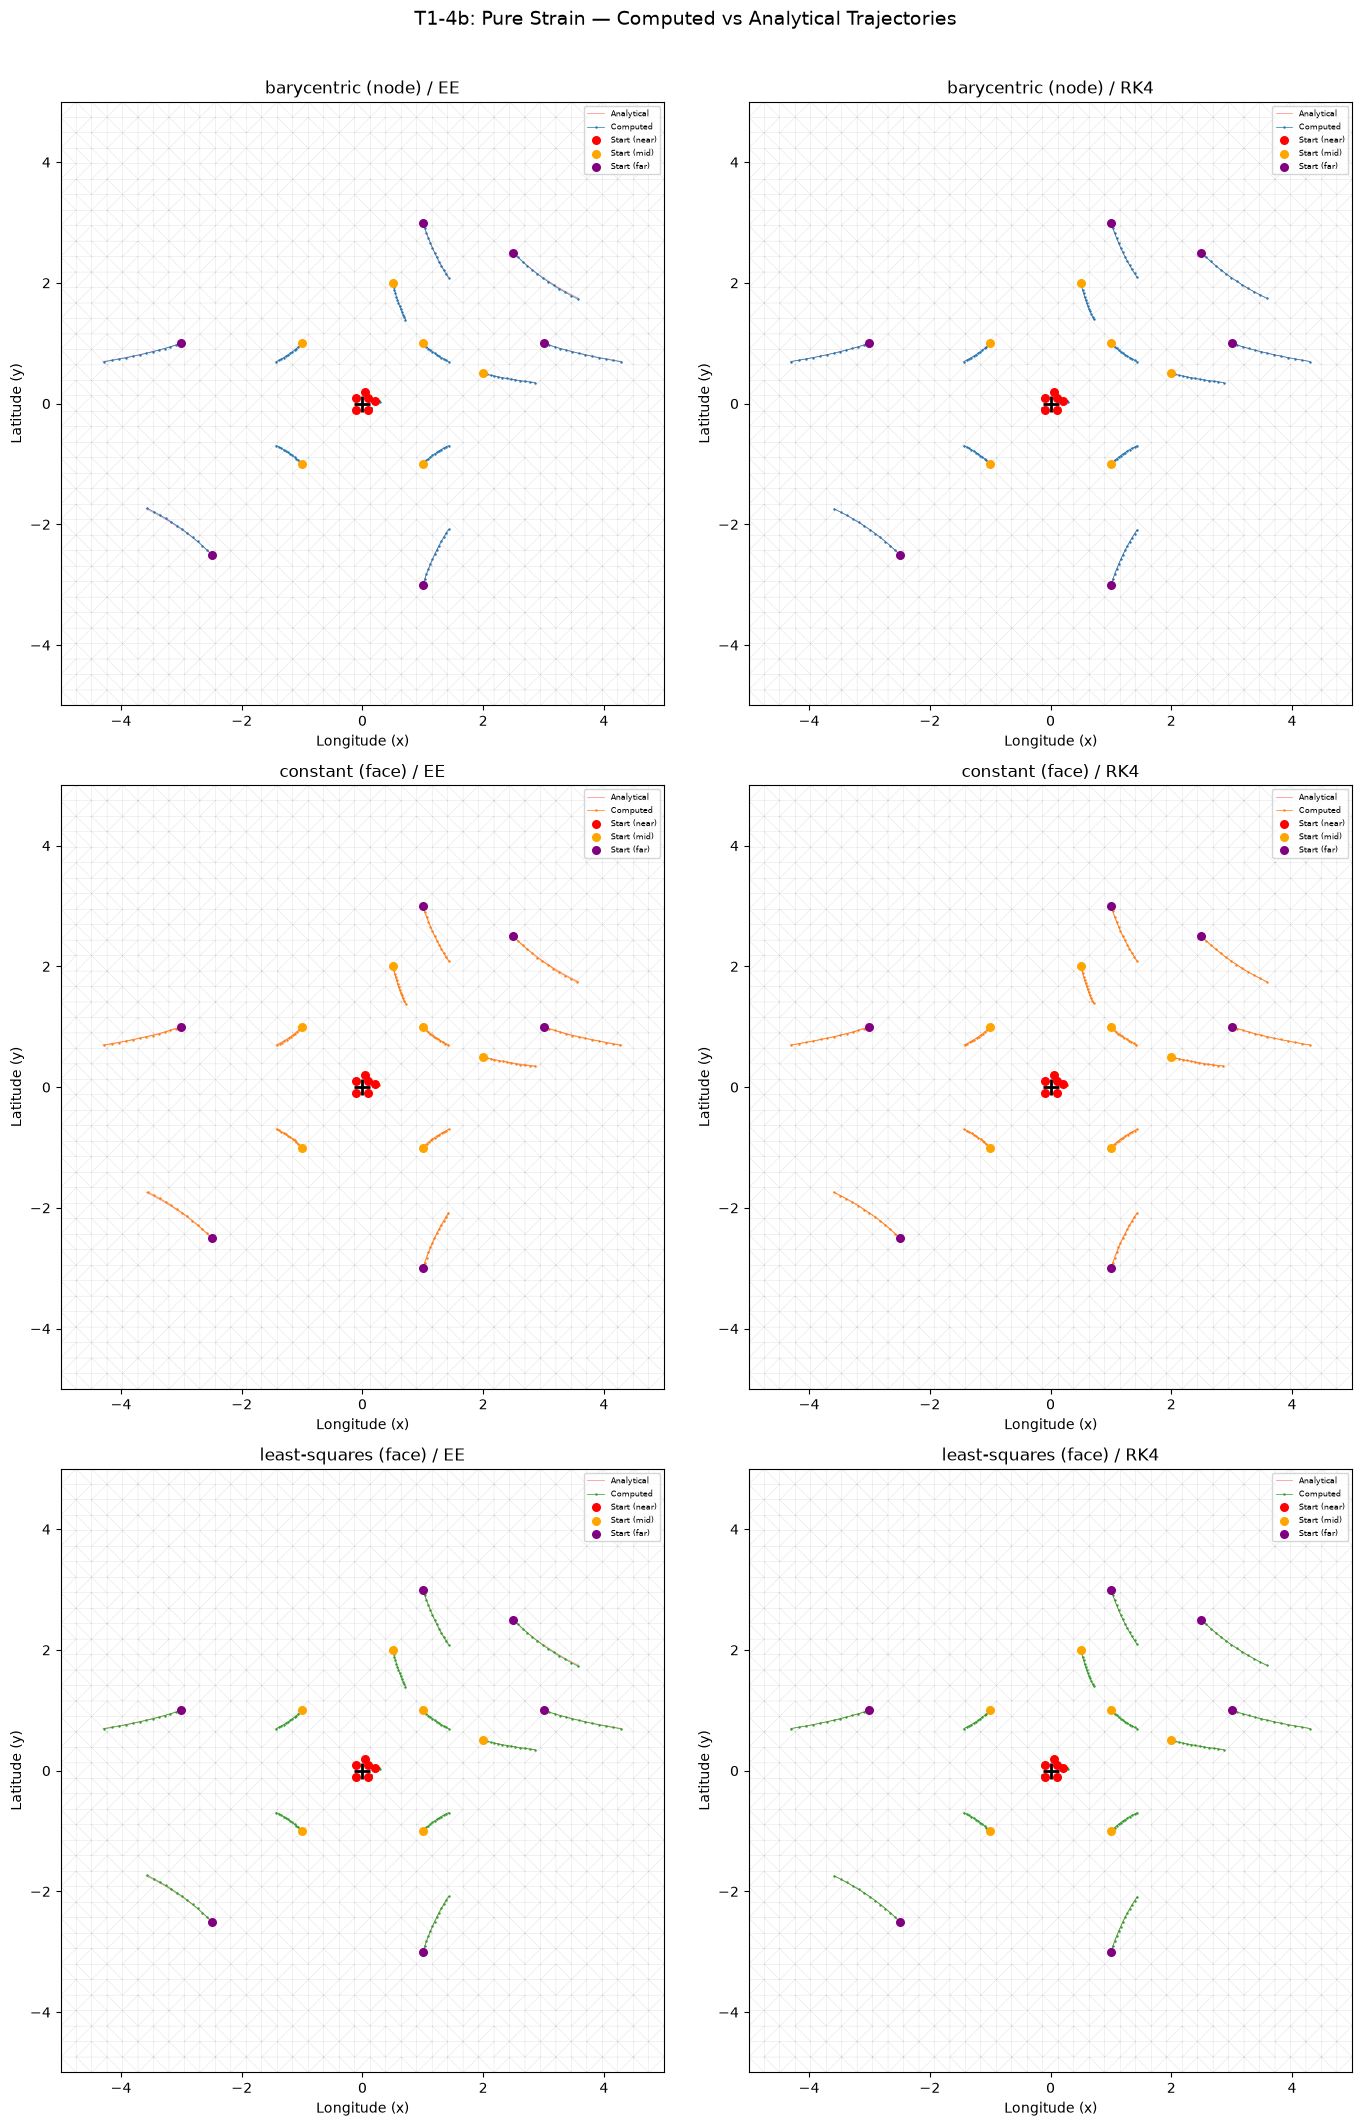

In [13]:
n_combos = len(output_files)
ncols = 2
nrows = math.ceil(n_combos / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 7 * nrows), squeeze=False)

t_fine = np.linspace(0, T_TOTAL_S, 500)

for idx, (label, out_path) in enumerate(output_files.items()):
    ax = axes[idx // ncols, idx % ncols]

    # Grid
    ax.triplot(triang, "k-", lw=0.2, alpha=0.2)

    # Analytical trajectories
    for i in range(N_PARTICLES):
        xa, ya = analytical_trajectory(p_lon0[i], p_lat0[i], EPSILON, t_fine)
        valid = (np.abs(xa) < HALF) & (np.abs(ya) < HALF)
        ax.plot(xa[valid], ya[valid], "r-", lw=0.6, alpha=0.4,
                label="Analytical" if i == 0 else None)

    # Computed trajectories from the parquet particle file
    traj_df = parcels.read_particlefile(out_path).sort("particle_id", "t")
    for p, pid in enumerate(traj_df["particle_id"].unique().sort()):
        traj = traj_df.filter(traj_df["particle_id"] == pid)
        lons = traj["x"].to_numpy()
        lats = traj["y"].to_numpy()
        ax.plot(lons, lats, color=SCHEME_COLORS[label.split(" / ")[0]], marker=".", ls="-", ms=1.5, lw=0.5,
                label="Computed" if p == 0 else None)

    # Color-coded start positions
    for group, color in colors_group.items():
        idx_g = [i for i, g in enumerate(particle_group) if g == group]
        ax.scatter(p_lon0[idx_g], p_lat0[idx_g], c=color, s=30, zorder=5,
                   label=f"Start ({group})")

    ax.plot(0, 0, "k+", ms=12, mew=2)
    ax.set_xlabel("Longitude (x)")
    ax.set_ylabel("Latitude (y)")
    ax.set_title(label)
    ax.legend(fontsize=6, loc="upper right")
    ax.set_aspect("equal")
    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)

for idx in range(n_combos, nrows * ncols):
    axes[idx // ncols, idx % ncols].set_visible(False)

fig.suptitle("T1-4b: Pure Strain — Computed vs Analytical Trajectories",
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 10. Convergence Study ($\Delta t$ refinement, all schemes)

As in T1-4: $T = 2520$ s with the near-origin particles only, so they stay inside the domain.
For the two linear schemes (barycentric node, least-squares face) the error should converge at the
integrator order. The constant-face scheme should plateau at its spatial error.

In [14]:
# T_CONV = 2520 s keeps the near-origin particles (|x0| <= 0.2) inside the domain: 0.2*exp(2.52) ~ 2.5.
# All DT_VALUES divide 2520.
DT_VALUES = [360, 180, 120, 60, 30, 15, 5]
T_CONV_S = 2520.0
T_CONV = np.timedelta64(int(T_CONV_S), "s")

p_lon_conv = p_lon0[:n_near].copy()
p_lat_conv = p_lat0[:n_near].copy()
lon_exact_conv, lat_exact_conv = analytical_position(p_lon_conv, p_lat_conv, EPSILON, T_CONV_S)

convergence_results = []
for scheme in SCHEMES:
    fieldset_conv = make_fieldset(scheme)
    for integrator_label, integrator in time_integrators.items():
        for dt_s in DT_VALUES:
            pset = parcels.ParticleSet(
                fieldset_conv,
                pclass=Particle64,
                x=p_lon_conv.copy(),
                y=p_lat_conv.copy(),
            )
            pset.execute(
                integrator,
                runtime=T_CONV,
                dt=np.timedelta64(dt_s, "s"),
                verbose_progress=False,
            )
            pos_err = np.sqrt((pset.x - lon_exact_conv)**2 + (pset.y - lat_exact_conv)**2)
            convergence_results.append({
                "scheme": scheme,
                "integrator": integrator_label,
                "dt_s": dt_s,
                "max_error": np.max(pos_err),
                "mean_error": np.mean(pos_err),
            })
            print(f"{scheme:22s} | {integrator_label:4s} | dt={dt_s:4d}s | max err = {np.max(pos_err):.4e}")

df_conv = pd.DataFrame(convergence_results)
df_conv

barycentric (node)     | EE   | dt= 360s | max err = 7.6464e-01


barycentric (node)     | EE   | dt= 180s | max err = 4.5627e-01
barycentric (node)     | EE   | dt= 120s | max err = 3.2495e-01


barycentric (node)     | EE   | dt=  60s | max err = 1.7431e-01


barycentric (node)     | EE   | dt=  30s | max err = 9.0436e-02


barycentric (node)     | EE   | dt=  15s | max err = 4.6083e-02


...

least-squares (face)   | RK4  | dt=  60s | max err = 6.4354e-07


least-squares (face)   | RK4  | dt=  30s | max err = 4.1239e-08


least-squares (face)   | RK4  | dt=  15s | max err = 2.6098e-09


least-squares (face)   | RK4  | dt=   5s | max err = 3.2490e-11


,scheme,integrator,dt_s,max_error,mean_error
0,barycentric (node),EE,360,7.646363e-01,4.142120e-01
1,barycentric (node),EE,180,4.562714e-01,2.471614e-01
2,barycentric (node),EE,120,3.249503e-01,1.760237e-01
3,barycentric (node),EE,60,1.743131e-01,9.442373e-02
4,barycentric (node),EE,30,9.043623e-02,4.898829e-02
5,barycentric (node),EE,15,4.608308e-02,2.496265e-02
6,barycentric (node),EE,5,1.555915e-02,8.428194e-03
7,barycentric (node),RK4,360,6.502124e-04,3.522562e-04
8,barycentric (node),RK4,180,4.720264e-05,2.557068e-05
9,barycentric (node),RK4,120,9.804536e-06,5.307963e-06


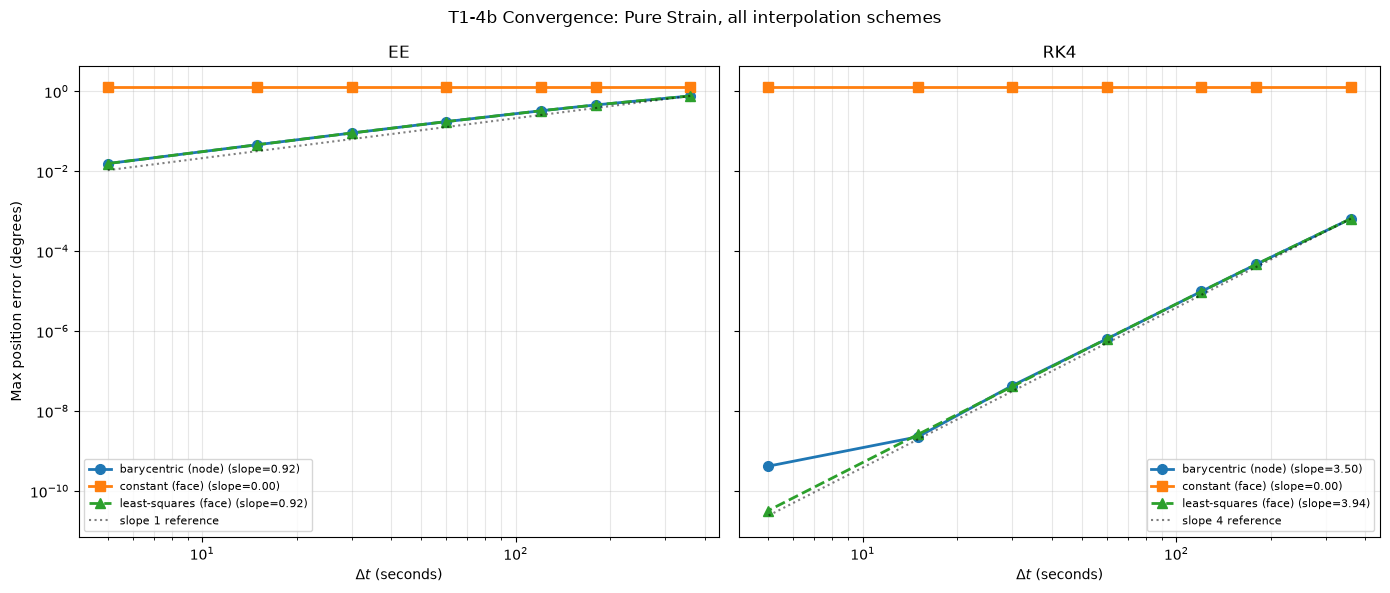

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
expected_orders = {"EE": 1, "RK4": 4}
markers = {"barycentric (node)": "o", "constant (face)": "s", "least-squares (face)": "^"}

for ax, integrator_label in zip(axes, time_integrators):
    for scheme in SCHEMES:
        sel = (df_conv["scheme"] == scheme) & (df_conv["integrator"] == integrator_label)
        dts = df_conv.loc[sel, "dt_s"].values.astype(float)
        errs = df_conv.loc[sel, "max_error"].values
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0] if np.all(errs > 0) else np.nan
        ax.loglog(dts, errs, marker=markers[scheme], color=SCHEME_COLORS[scheme], ms=7, lw=2,
                  ls="--" if scheme == "least-squares (face)" else "-",
                  label=f"{scheme} (slope={slope:.2f})")
    p = expected_orders[integrator_label]
    ref = df_conv.loc[(df_conv["scheme"] == "barycentric (node)") & (df_conv["integrator"] == integrator_label)]
    d = ref["dt_s"].values.astype(float)
    ax.loglog(d, ref["max_error"].values[0] * (d / d[0])**p, "k:", alpha=0.5, label=f"slope {p} reference")
    ax.set_xlabel(r"$\Delta t$ (seconds)")
    ax.set_title(f"{integrator_label}")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Max position error (degrees)")
fig.suptitle("T1-4b Convergence: Pure Strain, all interpolation schemes")
plt.tight_layout()
plt.show()

## 11. Error Amplification Over Time (RK4, dt = 30 s)

Track the maximum position error at every output step for each scheme.

INFO: Output files are stored in T1_4b_error_growth_barycentric.parquet


INFO: Output files are stored in T1_4b_error_growth_constant.parquet


INFO: Output files are stored in T1_4b_error_growth_least-squares.parquet


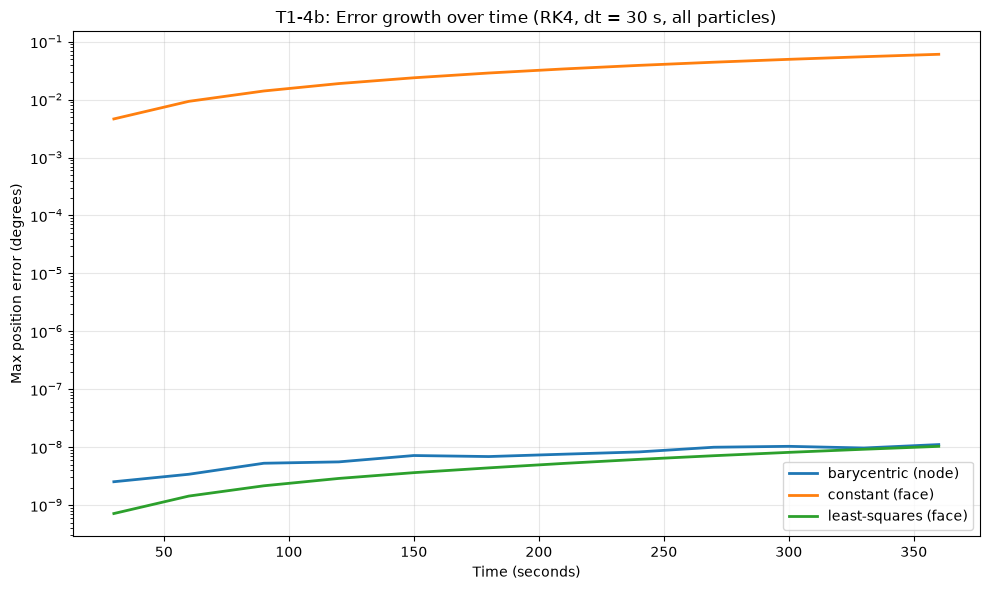

In [16]:
DT_TRACK = np.timedelta64(30, "s")

fig, ax = plt.subplots(figsize=(10, 6))
for scheme in SCHEMES:
    out_track = f"T1_4b_error_growth_{scheme.split(' ')[0]}.parquet"
    pset = parcels.ParticleSet(make_fieldset(scheme), pclass=Particle64, x=p_lon0.copy(), y=p_lat0.copy())
    pset.execute(
        parcels.kernels.AdvectionRK4,
        runtime=T_TOTAL,
        dt=DT_TRACK,
        output_file=parcels.ParticleFile(path=out_track, outputdt=DT_TRACK, mode="w"),
        verbose_progress=False,
    )
    traj_df = parcels.read_particlefile(out_track, decode_times=False).sort("t", "particle_id")
    t_all = traj_df["t"].to_numpy()
    pid = traj_df["particle_id"].to_numpy()
    x_all = traj_df["x"].to_numpy()
    y_all = traj_df["y"].to_numpy()
    t0 = t_all.min()

    time_s, max_err = [], []
    for t in np.unique(t_all):
        at_t = t_all == t
        elapsed = float(t - t0)
        lon_exact, lat_exact = analytical_position(p_lon0[pid[at_t]], p_lat0[pid[at_t]], EPSILON, elapsed)
        time_s.append(elapsed)
        max_err.append(np.max(np.hypot(x_all[at_t] - lon_exact, y_all[at_t] - lat_exact)))
    ax.semilogy(time_s[1:], max_err[1:], "-", color=SCHEME_COLORS[scheme], lw=2, label=scheme)
    os.remove(out_track)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Max position error (degrees)")
ax.set_title("T1-4b: Error growth over time (RK4, dt = 30 s, all particles)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11b. Time-Step Refinement to Machine Precision

How small must $\Delta t$ be for the trajectory error to reach float64 machine precision ($\sim 10^{-16}$)?
We continue the convergence study (near-origin particles, $T = 2520$ s, RK4) to sub-second time steps.

- **least-squares (face):** the interpolation is exact to round-off, so the error is pure RK4 truncation
  $\propto \Delta t^4$ until it meets the float64 round-off floor. The final positions here are $|x| \approx 0.6$–$2.5$,
  where one float64 unit in the last place (ulp) is $1.1$–$4.4\times10^{-16}$.
- **barycentric (node):** limited by Parcels' float32 barycentric weights (velocity error $\sim 10^{-10}$),
  so it cannot get below $\sim 10^{-10}$ at any $\Delta t$ — only $\Delta t \geq 1$ s is run.
- **constant (face):** dominated by spatial error ($\sim 1$), not run here.

Small $\Delta t$ means many steps: this cell takes several minutes (the $\Delta t = 0.125$ s run alone is ~4 min).

In [17]:
import time

DT_FINE = {"least-squares (face)": [5.0, 2.5, 1.0, 0.5, 0.25, 0.125],
           "barycentric (node)":   [5.0, 2.5, 1.0]}

fine_results = []
for scheme, dts in DT_FINE.items():
    fieldset_fine = make_fieldset(scheme)
    for dt_s in dts:
        t_wall = time.time()
        pset = parcels.ParticleSet(fieldset_fine, pclass=Particle64,
                                   x=p_lon_conv.copy(), y=p_lat_conv.copy())
        pset.execute(
            parcels.kernels.AdvectionRK4,
            runtime=np.timedelta64(int(T_CONV_S * 1000), "ms"),
            dt=np.timedelta64(int(dt_s * 1000), "ms"),   # milliseconds: allows sub-second dt
            verbose_progress=False,
        )
        pos_err = np.sqrt((pset.x - lon_exact_conv)**2 + (pset.y - lat_exact_conv)**2)
        fine_results.append({"scheme": scheme, "dt_s": dt_s, "n_steps": int(T_CONV_S / dt_s),
                             "mean_error": pos_err.mean(), "max_error": pos_err.max(),
                             "wall_s": time.time() - t_wall})
        print(f"{scheme:22s} | dt={dt_s:6.3f}s | steps={int(T_CONV_S / dt_s):6d} | "
              f"mean err = {pos_err.mean():.2e}  max err = {pos_err.max():.2e}  ({time.time() - t_wall:.0f} s)")

df_fine = pd.DataFrame(fine_results)
df_fine

least-squares (face)   | dt= 5.000s | steps=   504 | mean err = 1.76e-11  max err = 3.25e-11  (6 s)


least-squares (face)   | dt= 2.500s | steps=  1008 | mean err = 1.10e-12  max err = 2.03e-12  (11 s)


least-squares (face)   | dt= 1.000s | steps=  2520 | mean err = 3.42e-14  max err = 6.31e-14  (28 s)


least-squares (face)   | dt= 0.500s | steps=  5040 | mean err = 4.89e-16  max err = 8.89e-16  (56 s)


least-squares (face)   | dt= 0.250s | steps= 10080 | mean err = 5.29e-15  max err = 9.77e-15  (112 s)


least-squares (face)   | dt= 0.125s | steps= 20160 | mean err = 4.72e-15  max err = 8.44e-15  (221 s)


barycentric (node)     | dt= 5.000s | steps=   504 | mean err = 1.82e-10  max err = 4.19e-10  (14 s)


barycentric (node)     | dt= 2.500s | steps=  1008 | mean err = 1.45e-09  max err = 2.72e-09  (25 s)


barycentric (node)     | dt= 1.000s | steps=  2520 | mean err = 4.85e-10  max err = 9.10e-10  (63 s)


,scheme,dt_s,n_steps,mean_error,max_error,wall_s
0,least-squares (face),5.000,504,1.759970e-11,3.249050e-11,6.266919
1,least-squares (face),2.500,1008,1.102199e-12,2.034819e-12,11.146474
2,least-squares (face),1.000,2520,3.415881e-14,6.306073e-14,27.594631
3,least-squares (face),0.500,5040,4.887622e-16,8.887898e-16,56.235487
4,least-squares (face),0.250,10080,5.292320e-15,9.769981e-15,111.529685
5,least-squares (face),0.125,20160,4.718541e-15,8.437705e-15,220.979776
6,barycentric (node),5.000,504,1.823644e-10,4.186087e-10,13.948858
7,barycentric (node),2.500,1008,1.450727e-09,2.720507e-09,25.294719
8,barycentric (node),1.000,2520,4.852078e-10,9.099181e-10,63.476585


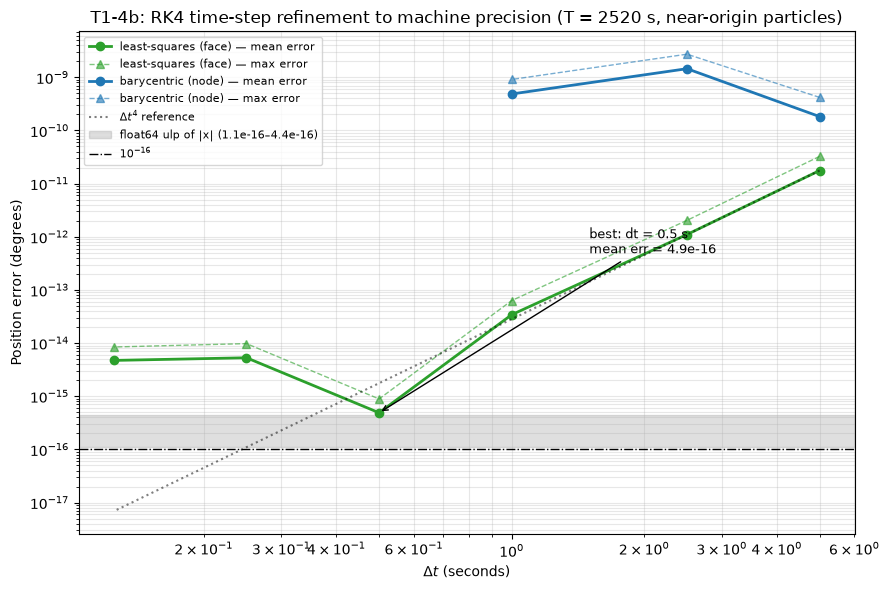

least-squares reaches its minimum mean error 4.89e-16 at dt = 0.5 s (float64 ulp of |x| here: 1.1e-16–4.4e-16).
Below that dt the error grows again: truncation is already below round-off, so extra steps only add round-off.


In [18]:
ulp_lo, ulp_hi = np.spacing(np.abs(lon_exact_conv).min()), np.spacing(np.abs(lon_exact_conv).max())

fig, ax = plt.subplots(figsize=(9, 6))
for scheme in DT_FINE:
    sel = df_fine["scheme"] == scheme
    ax.loglog(df_fine.loc[sel, "dt_s"], df_fine.loc[sel, "mean_error"], marker="o", lw=2,
              color=SCHEME_COLORS[scheme], label=f"{scheme} — mean error")
    ax.loglog(df_fine.loc[sel, "dt_s"], df_fine.loc[sel, "max_error"], marker="^", lw=1, ls="--",
              color=SCHEME_COLORS[scheme], alpha=0.6, label=f"{scheme} — max error")

# RK4 reference slope anchored at the coarsest least-squares point
ls = df_fine[df_fine["scheme"] == "least-squares (face)"]
d = np.array(DT_FINE["least-squares (face)"])
ax.loglog(d, ls["mean_error"].values[0] * (d / d[0])**4, "k:", alpha=0.5, label=r"$\Delta t^4$ reference")

ax.axhspan(ulp_lo, ulp_hi, color="grey", alpha=0.25, label=f"float64 ulp of |x| ({ulp_lo:.1e}–{ulp_hi:.1e})")
ax.axhline(1e-16, color="k", lw=1, ls="-.", label=r"$10^{-16}$")

best = ls.loc[ls["mean_error"].idxmin()]
ax.annotate(f"best: dt = {best.dt_s:g} s\nmean err = {best.mean_error:.1e}",
            xy=(best.dt_s, best.mean_error), xytext=(best.dt_s * 3, best.mean_error * 1e3),
            arrowprops=dict(arrowstyle="->"), fontsize=9)

ax.set_xlabel(r"$\Delta t$ (seconds)")
ax.set_ylabel("Position error (degrees)")
ax.set_title(f"T1-4b: RK4 time-step refinement to machine precision (T = {T_CONV_S:.0f} s, near-origin particles)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

print(f"least-squares reaches its minimum mean error {best.mean_error:.2e} at dt = {best.dt_s:g} s "
      f"(float64 ulp of |x| here: {ulp_lo:.1e}–{ulp_hi:.1e}).")
print("Below that dt the error grows again: truncation is already below round-off, so extra steps only add round-off.")

## 12. Verification Assertions

1. **Exactness of the linear schemes:** barycentric (node) and least-squares (face) must reproduce the
   linear field. Threshold `1e-8` on the velocity: the node scheme is limited by Parcels' float32
   barycentric weights (~1e-10 here), the least-squares scheme is exact to float64 round-off.
2. **Convergence order** (both linear schemes): measured slope within 0.5 of the integrator order.
3. **RK4 accuracy at the finest dt** (both linear schemes): error `< 1e-4`, as in T1-4.
4. **Linear schemes agree:** after the main run, least-squares and barycentric RK4 errors differ by `< 1e-6`.
5. **Constant (face) sanity:** runs complete with bounded error `< 5.0` (as in T1-4), and its error is
   larger than that of both linear schemes (it is the only scheme with spatial error).

In [19]:
all_pass = True


def check(ok, msg):
    global all_pass
    all_pass &= bool(ok)
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")


LINEAR = ["barycentric (node)", "least-squares (face)"]
res = {(r["scheme"], r["integrator"]): r for r in results}
interp_err = dict(zip(df_interp["scheme"], df_interp["max_velocity_error"]))

print("=== 1. Exact interpolation of the linear field ===")
for scheme in LINEAR:
    check(interp_err[scheme] < 1e-8, f"{scheme}: max velocity error = {interp_err[scheme]:.2e} (< 1e-8)")

print("\n=== 2. Convergence order ===")
for scheme in LINEAR:
    for integrator_label, expected in expected_orders.items():
        sel = (df_conv["scheme"] == scheme) & (df_conv["integrator"] == integrator_label)
        dts = df_conv.loc[sel, "dt_s"].values.astype(float)
        errs = df_conv.loc[sel, "max_error"].values
        slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
        check(abs(slope - expected) < 0.5, f"{scheme} / {integrator_label}: slope = {slope:.2f}, expected ~ {expected}")

print("\n=== 3. RK4 accuracy at finest dt ===")
for scheme in LINEAR:
    err = df_conv.loc[(df_conv["scheme"] == scheme) & (df_conv["integrator"] == "RK4")
                      & (df_conv["dt_s"] == min(DT_VALUES)), "max_error"].values[0]
    check(err < 1e-4, f"{scheme}: RK4 max error at dt={min(DT_VALUES)}s = {err:.4e} (< 1e-4)")

print("\n=== 4. Least-squares agrees with barycentric (RK4, main run) ===")
d = abs(res[("least-squares (face)", "RK4")]["max_position_error"] - res[("barycentric (node)", "RK4")]["max_position_error"])
check(d < 1e-6, f"|err_lsq - err_node| = {d:.2e} (< 1e-6)")

print("\n=== 5. Constant (face) sanity ===")
for integrator_label in time_integrators:
    e_face = res[("constant (face)", integrator_label)]["max_position_error"]
    check(e_face < 5.0, f"constant (face) / {integrator_label}: max err = {e_face:.4e} (< 5.0)")
e_face = res[("constant (face)", "RK4")]["max_position_error"]
for scheme in LINEAR:
    e = res[(scheme, "RK4")]["max_position_error"]
    check(e_face > e, f"constant (face) RK4 err {e_face:.2e} > {scheme} RK4 err {e:.2e}")

print()
if all_pass:
    print("T1-4b PASSED: All checks within tolerance.")
else:
    raise AssertionError("T1-4b FAILED: One or more checks exceeded tolerance.")

=== 1. Exact interpolation of the linear field ===
  [PASS] barycentric (node): max velocity error = 4.73e-10 (< 1e-8)
  [PASS] least-squares (face): max velocity error = 1.23e-18 (< 1e-8)

=== 2. Convergence order ===
  [PASS] barycentric (node) / EE: slope = 0.92, expected ~ 1
  [PASS] barycentric (node) / RK4: slope = 3.50, expected ~ 4
  [PASS] least-squares (face) / EE: slope = 0.92, expected ~ 1
  [PASS] least-squares (face) / RK4: slope = 3.94, expected ~ 4

=== 3. RK4 accuracy at finest dt ===
  [PASS] barycentric (node): RK4 max error at dt=5s = 4.1861e-10 (< 1e-4)
  [PASS] least-squares (face): RK4 max error at dt=5s = 3.2490e-11 (< 1e-4)

=== 4. Least-squares agrees with barycentric (RK4, main run) ===
  [PASS] |err_lsq - err_node| = 7.63e-10 (< 1e-6)

=== 5. Constant (face) sanity ===
  [PASS] constant (face) / EE: max err = 6.0566e-02 (< 5.0)
  [PASS] constant (face) / RK4: max err = 6.0566e-02 (< 5.0)
  [PASS] constant (face) RK4 err 6.06e-02 > barycentric (node) RK4 err 

## 13. Cleanup

In [20]:
for out_path in output_files.values():
    if os.path.exists(out_path):
        os.remove(out_path)
print("Temporary output cleaned up.")

Temporary output cleaned up.
